In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Load your dataset directly
df = pd.read_csv("music_mood_dataset.csv")

# Quick verification
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nMood Distribution:")
print(df['Mood'].value_counts())

Dataset Shape: (586672, 10)

First 5 Rows:


,name,artists,danceability,energy,loudness,acousticness,instrumentalness,valence,tempo,Mood
0,Carve,['Uli'],0.645,0.4450,-13.338,0.674,0.7440,0.127,104.851,Calm
1,Capítulo 2.16 - Banquero Anarquista,['Fernando Pessoa'],0.695,0.2630,-22.136,0.797,0.0000,0.655,102.009,Happy
2,Vivo para Quererte - Remasterizado,['Ignacio Corsini'],0.434,0.1770,-21.180,0.994,0.0218,0.457,130.418,Sad
3,El Prisionero - Remasterizado,['Ignacio Corsini'],0.321,0.0946,-27.961,0.995,0.9180,0.397,169.980,Calm
4,Lady of the Evening,['Dick Haymes'],0.402,0.1580,-16.900,0.989,0.1300,0.196,103.220,Sad



Mood Distribution:
Mood
Sad          212113
Energetic    180274
Happy        152960
Calm          41325
Name: count, dtype: int64


In [3]:
# Data Imputation (Handling Missing Values)
import pandas as pd

# Load dataset
df = pd.read_csv("music_mood_dataset.csv")

# 1. Check missing values before imputation
print("Missing values before imputation:")
print(df.isnull().sum())

# 2. Impute missing text values in 'name' column with a placeholder
df['name'] = df['name'].fillna('Unknown Track')

# (Optional) If any numerical columns ever have missing values, impute using mean/median:
# df['tempo'] = df['tempo'].fillna(df['tempo'].median())

# 3. Verify missing values after imputation
print("\nMissing values after imputation:")
print(df.isnull().sum())

Missing values before imputation:
name                71
artists              0
danceability         0
energy               0
loudness             0
acousticness         0
instrumentalness     0
valence              0
tempo                0
Mood                 0
dtype: int64

Missing values after imputation:
name                0
artists             0
danceability        0
energy              0
loudness            0
acousticness        0
instrumentalness    0
valence             0
tempo               0
Mood                0
dtype: int64


In [4]:
# Encoding
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
label_encoder = LabelEncoder()

# Fit and transform the 'Mood' column into numeric IDs (0, 1, 2, 3)
df['Mood_encoded'] = label_encoder.fit_transform(df['Mood'])

# Generate and print the explicit class mapping dictionary
class_mapping = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))

print("Class Mapping Dictionary:")
print(class_mapping)

print("\nSample Encoded Values:")
print(df[['Mood', 'Mood_encoded']].head(10))

Class Mapping Dictionary:
{'Calm': 0, 'Energetic': 1, 'Happy': 2, 'Sad': 3}

Sample Encoded Values:
    Mood  Mood_encoded
0   Calm             0
1  Happy             2
2    Sad             3
3   Calm             0
4    Sad             3
5    Sad             3
6    Sad             3
7    Sad             3
8    Sad             3
9   Calm             0


In [5]:
# Normalization / Feature Scaling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Define feature matrix (X) and target array (y)
feature_cols = [
    'danceability', 'energy', 'loudness', 
    'acousticness', 'instrumentalness', 'valence', 'tempo'
]

X = df[feature_cols]
y = df['Mood_encoded']

# 2. Train-Test Split prior to scaling (prevents data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Fit scaler ONLY on training set, then transform both train & test sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back to DataFrames for easy inspection
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=feature_cols)

print("Scaled Features Sample (Training Set):")
display(X_train_scaled_df.head())

Scaled Features Sample (Training Set):


,danceability,energy,loudness,acousticness,instrumentalness,valence,tempo
0,-1.134852,0.480140,0.208285,-1.285249,-0.424833,0.511412,1.815877
1,0.978651,0.996061,0.688538,-0.949251,-0.424819,1.438928,0.108580
2,-0.430351,1.635009,1.104588,-1.277077,1.055950,-0.874040,0.165885
3,-0.665184,-1.174775,-1.312191,1.287296,-0.424420,-0.225944,0.714068
4,-2.062144,-0.341364,-0.082695,0.923140,-0.424844,-0.842994,-1.797288


In [6]:
#Data Processing & Feature Preparation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# 1. Handle Missing Values
# Fill missing track names with a placeholder to keep metadata intact
df['name'] = df['name'].fillna('Unknown Track')

# 2. Select Features (X) and Target Label (y)
feature_cols = [
    'danceability', 'energy', 'loudness', 
    'acousticness', 'instrumentalness', 'valence', 'tempo'
]
X = df[feature_cols]
y = df['Mood']

# 3. Encode Categorical Target Labels into Numerical Class IDs
# Calm: 0, Energetic: 1, Happy: 2, Sad: 3
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# 4. Train-Test Split (80% Train, 20% Test)
# Stratification ensures equal target distribution between train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# 5. Feature Scaling (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data processing complete!")
print("Training Set Shape:", X_train_scaled.shape)
print("Testing Set Shape :", X_test_scaled.shape)
print("Classes mapping:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

Data processing complete!
Training Set Shape: (469337, 7)
Testing Set Shape : (117335, 7)
Classes mapping: {'Calm': 0, 'Energetic': 1, 'Happy': 2, 'Sad': 3}


In [7]:
#Digitization
# Represent the processed table as an array and inspect its dimensions
source_df = df_processed if "df_processed" in globals() else df

# Full table as a NumPy object array (mixed types preserved, if any remain)
table_array = source_df.to_numpy()
print("Source DataFrame shape:", source_df.shape)
print("Full table array type:", type(table_array))
print("Full table array shape (rows, columns):", table_array.shape)
print("Full table array ndim:", table_array.ndim)
print()
print("First 3 rows of the array:")
print(table_array[:3])
print()

# Numeric-only view (common ML input form)
numeric_only = source_df.select_dtypes(include=[np.number])
numeric_array = numeric_only.to_numpy()
print("Numeric columns:", list(numeric_only.columns))
print("Numeric array shape (rows, features):", numeric_array.shape)
print("Numeric array dtype:", numeric_array.dtype)
print()
print("First 5 numeric rows:")
print(numeric_array[:5])

Source DataFrame shape: (586672, 11)
Full table array type: <class 'numpy.ndarray'>
Full table array shape (rows, columns): (586672, 11)
Full table array ndim: 2

First 3 rows of the array:
[['Carve' "['Uli']" 0.645 0.445 -13.338 0.674 0.744 0.127 104.851 'Calm'
  0]
 ['Capítulo 2.16 - Banquero Anarquista' "['Fernando Pessoa']" 0.695 0.263
  -22.136 0.797 0.0 0.655 102.009 'Happy' 2]
 ['Vivo para Quererte - Remasterizado' "['Ignacio Corsini']" 0.434 0.177
  -21.18 0.994 0.0218 0.457 130.418 'Sad' 3]]

Numeric columns: ['danceability', 'energy', 'loudness', 'acousticness', 'instrumentalness', 'valence', 'tempo', 'Mood_encoded']
Numeric array shape (rows, features): (586672, 8)
Numeric array dtype: float64

First 5 numeric rows:
[[ 6.45000e-01  4.45000e-01 -1.33380e+01  6.74000e-01  7.44000e-01
   1.27000e-01  1.04851e+02  0.00000e+00]
 [ 6.95000e-01  2.63000e-01 -2.21360e+01  7.97000e-01  0.00000e+00
   6.55000e-01  1.02009e+02  2.00000e+00]
 [ 4.34000e-01  1.77000e-01 -2.11800e+01  9.9

In [8]:
# Exploratory Data Analysis (EDA)
# 1. Inspect Dataset Shapes & Data Types
print("=== DATASET OVERVIEW ===")
print(f"Total Rows (Tracks): {source_df.shape[0]:,}")
print(f"Total Columns: {source_df.shape[1]}")
print("\nData Types:")
print(source_df.dtypes)

# 2. Check for Missing Values & Duplicates
print("\n=== DATA QUALITY AUDIT ===")
print("Missing Values per Column:")
print(source_df.isnull().sum())
print(f"\nDuplicate Rows Count: {source_df.duplicated().sum()}")

# 3. Summary Statistics for Numeric Audio Features
print("\n=== NUMERICAL FEATURES SUMMARY ===")
numeric_cols = source_df.select_dtypes(include=[np.number]).columns
print(source_df[numeric_cols].describe().T[['mean', 'std', 'min', '50%', 'max']])

# 4. Target Class Frequency & Proportions
print("\n=== TARGET CLASS DISTRIBUTION ===")
class_counts = source_df['Mood'].value_counts()
class_percentages = source_df['Mood'].value_counts(normalize=True) * 100
class_summary = pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_percentages.round(2)})
print(class_summary)

=== DATASET OVERVIEW ===
Total Rows (Tracks): 586,672
Total Columns: 11

Data Types:
name                    str
artists                 str
danceability        float64
energy              float64
loudness            float64
acousticness        float64
instrumentalness    float64
valence             float64
tempo               float64
Mood                    str
Mood_encoded          int64
dtype: object

=== DATA QUALITY AUDIT ===
Missing Values per Column:
name                0
artists             0
danceability        0
energy              0
loudness            0
acousticness        0
instrumentalness    0
valence             0
tempo               0
Mood                0
Mood_encoded        0
dtype: int64

Duplicate Rows Count: 17907

=== NUMERICAL FEATURES SUMMARY ===
                        mean        std   min         50%      max
danceability        0.563594   0.166103   0.0    0.577000    0.991
energy              0.542036   0.251923   0.0    0.549000    1.000
loudness         

C:\Users\Amri\AppData\Local\Temp\ipykernel_24608\423916676.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=source_df, x='Mood', palette='magma')


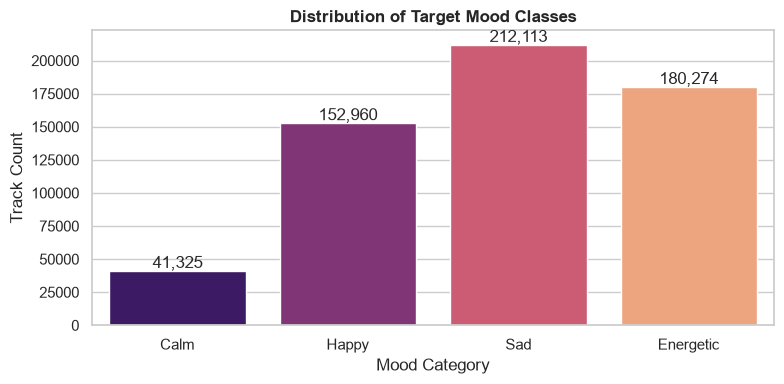

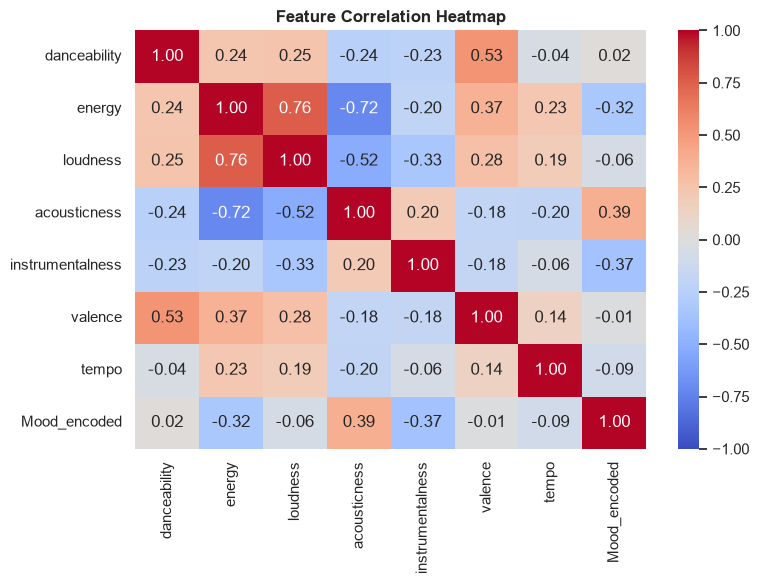

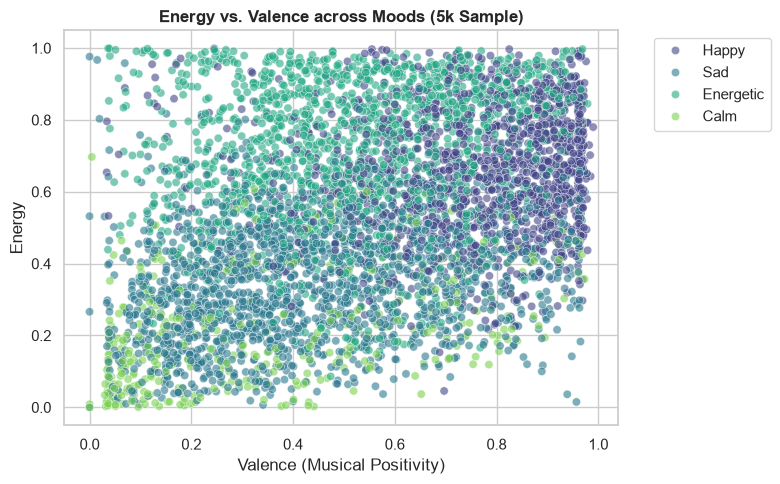

C:\Users\Amri\AppData\Local\Temp\ipykernel_24608\423916676.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=source_df, x='Mood', y='danceability', palette='Set2')


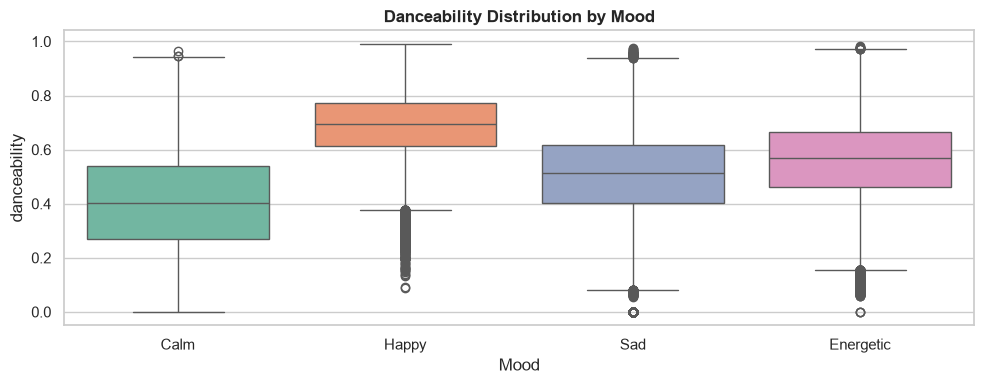

In [9]:
# Data Visualization
# Set overall aesthetic theme
sns.set_theme(style="whitegrid", palette="muted")

# 1. Target Mood Class Balance
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=source_df, x='Mood', palette='magma')
plt.title('Distribution of Target Mood Classes', fontweight='bold', fontsize=12)
plt.xlabel('Mood Category')
plt.ylabel('Track Count')

# Add values above bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.show()

# 2. Correlation Heatmap of Numeric Features
plt.figure(figsize=(8, 6))
numeric_df = source_df.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=True)
plt.title('Feature Correlation Heatmap', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

# 3. Energy vs. Valence Scatter Plot (Mood Separability)
plt.figure(figsize=(8, 5))
# Sample 5,000 points for clean rendering on large datasets
sample_df = source_df.sample(n=min(5000, len(source_df)), random_state=42)

sns.scatterplot(
    data=sample_df, 
    x='valence', y='energy', hue='Mood', 
    alpha=0.6, palette='viridis'
)
plt.title('Energy vs. Valence across Moods (5k Sample)', fontweight='bold', fontsize=12)
plt.xlabel('Valence (Musical Positivity)')
plt.ylabel('Energy')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 4. Feature Distribution Plots Across Moods
plt.figure(figsize=(10, 4))
sns.boxplot(data=source_df, x='Mood', y='danceability', palette='Set2')
plt.title('Danceability Distribution by Mood', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()